# GS widget

Play with `GSWidget` from the buttons. Create, Regenerate engine, Run, Save, and Load do not block this notebook: engine build and `GS.run` run on a worker thread. After the status line says the engine is ready, `gui.engine` is that instance.

Leave the label blank to save without a prefix. Load picks a `settings.json`; masks in the same folder are restored when the shapes match.

An engine you already built can be passed in: `GSWidget(engine)`. The cell under the empty widget does that for modes 0 to 2.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
%gui qt
import sys
from pathlib import Path

_algorithms = Path(r"C:\Users\ModeLabQBI\LAB\algorithms\GS").resolve().parent
if str(_algorithms) not in sys.path:
    sys.path.append(str(_algorithms))
import GS

sys.modules["gs"] = GS

from gs.ui import GSWidget

# Start GS Widget without a GS engine

In [2]:

gui = GSWidget()
gui.show()
gui

<gs.ui.widget.GSWidget(0x1df5ade33f0) at 0x000001DF5D5BFEC0>

# Pass to the Widget a GS Engine

In [10]:
from gs import GS, GS_mask_setup, optical_setup

optical = optical_setup(
    wavelength=0.8435,
    fin=20e3,
    fout=4.7e3,
    masksize=960,
    slm_pixel_size=9.2,
    MMF_mfd=5.34,  # estimated MFD for the double clad with 4 um inner core
    MMF_diameter=23,
    MMF_mode_groups=17,
    W0_slm=2.2 * 1e3,  # um
    mode_basis="LG",
)
# optical = optical_setup(
#     wavelength=1.3,
#     fin=25e3,
#     fout=8e3,
#     masksize=960,
#     slm_pixel_size=9.2,
#     MMF_mfd=12.2,
#     MMF_diameter=62.5,
#     MMF_mode_groups=22,
#     mode_basis="LG",
# )

high_frequencies_factor = 3
masksetup = GS_mask_setup(
    num_masks=2,
    convergence_metric="overlap",
    goal_value=0.99,
    minium_efficiency=0.1,
    downscale=2,
    upsample=0,
    MAX_iterations=80,
    filtering=True,
    filtering_factor=0.5,
    filtering_mask_radius_factor=high_frequencies_factor,
)

gs_engine = GS(optical, masksetup, engine_mode="fibremodes")
#gs_engine = GS(optical, masksetup, engine_mode="fibremodes", mode_range=(0, 2))

gui = GSWidget(gs_engine)
gui.show()
gui

ENGINE MODE SELECTED: fibremodes
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 0.4488734148550725 um
MAX spectral distance +- 107.0 um
Beam waist in the SLM --> 2.2  mm , Calculated via:  Custom Beam Waist  Pupil included: False
Forbiden area r < 34.5 um
Generating modes coeficients...
Generating modes...
Engine : GPU
Mem. avaliable  12.0595703125  mem. needed  0.30590057373046875  in Gb
Generating rest of the modes...
MODES RANGE: None
Fibre modes engine mode selected: memory allocation for 153 masks --> number of modes 81
--------------------------------
Feasibility setup integrity check:
Illumination outside pupil power: 0.29 % --> True
Modes outside aperture power: 0.00 % --> True
Illumination overlap support: True
Setup feasible?  True
This system support up to NA_MMF: 0.43
--------------------------------


<gs.ui.widget.GSWidget(0x24d3fa29890) at 0x0000024CC256D380>

ENGINE MODE SELECTED: fibremodes
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 0.4488734148550725 um
MAX spectral distance +- 107.0 um
Beam waist in the SLM --> 2.2  mm , Calculated via:  Custom Beam Waist  Pupil included: False
Forbiden area r < 34.5 um
Generating modes coeficients...
Generating modes...
Engine : GPU
Mem. avaliable  11.4775390625  mem. needed  0.6382369995117188  in Gb
Generating rest of the modes...
MODES RANGE: None
Fibre modes engine mode selected: memory allocation for 325 masks --> number of modes 169
--------------------------------
Feasibility setup integrity check:
Illumination outside pupil power: 0.29 % --> True
Modes outside aperture power: 0.00 % --> True
Illumination overlap support: True
Setup feasible?  True
This system support up to NA_MMF: 0.43
--------------------------------
ENGINE MODE SELECTED: fibremodes
SLM size = 8832.0 u

In [4]:
from pylab import *
from visualization import complexToRGB

In [5]:
gs_engine = gui.engine
modes = gs_engine.modes.modes_array
modes_SLM = fftshift(ifft2(fftshift(modes, axes = (1,2)), axes = (1,2)), axes = (1,2))
incohe_modes_SLM = sum(abs(modes_SLM[:,...]), axis = 0)
incohe_modes_SLM /=incohe_modes_SLM.max()



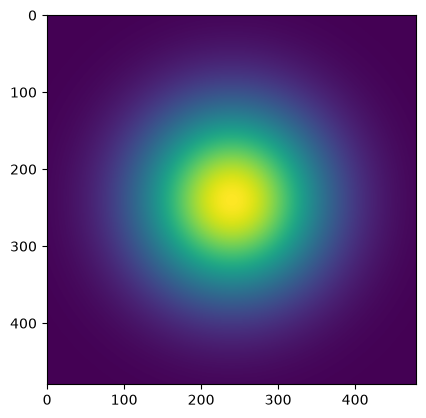

In [6]:
imshow(gs_engine.illumination.ILLUMINATION)

In [7]:
illumination = gs_engine.illumination.ILLUMINATION
illumination_norm = illumination / illumination.max()

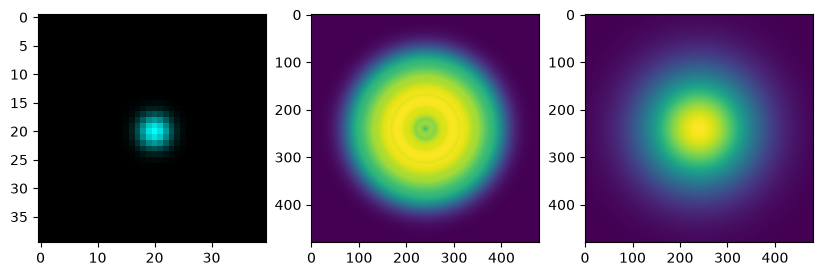

In [8]:
cc = modes.shape[1]//2
window = 20
target_idx = 0
fig, ax = subplots(1,3, figsize = (10,5))

ax[0].imshow(complexToRGB(modes[target_idx,...][cc-window:cc+window, cc-window:cc+window]))
ax[1].imshow(incohe_modes_SLM)
ax[2].imshow(illumination)

In [9]:
highest_order_mode = abs(modes_SLM[-2, cc, :])
highest_order_mode /= highest_order_mode.max()

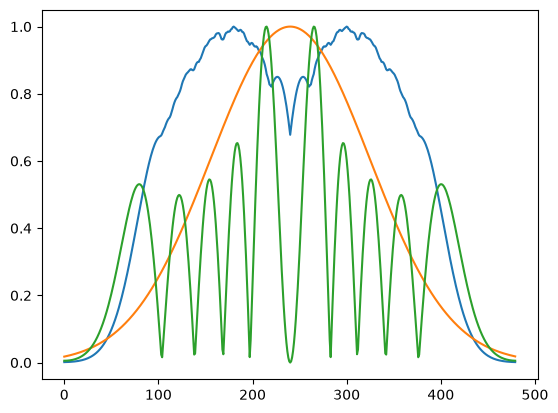

In [10]:
plot(incohe_modes_SLM[cc, :])
plot(illumination_norm[cc, :])
plot(highest_order_mode)


In [11]:
thr_modes_incoh = zeros_like(incohe_modes_SLM)
thr = 0.1
thr_modes_incoh[incohe_modes_SLM>=thr] = 1

thr_illumination = zeros_like(illumination_norm)
thr_illumination[illumination_norm>=thr] = 1

combined = thr_illumination + thr_modes_incoh

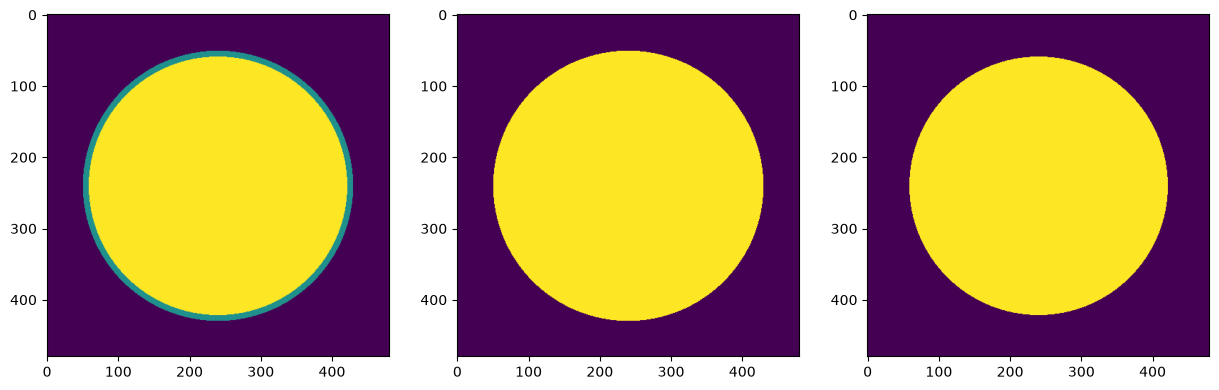

In [12]:
fig, ax = subplots(1,3, figsize = (15,5))
ax[0].imshow(combined)
ax[1].imshow(thr_modes_incoh)
ax[2].imshow(thr_illumination)



51
429


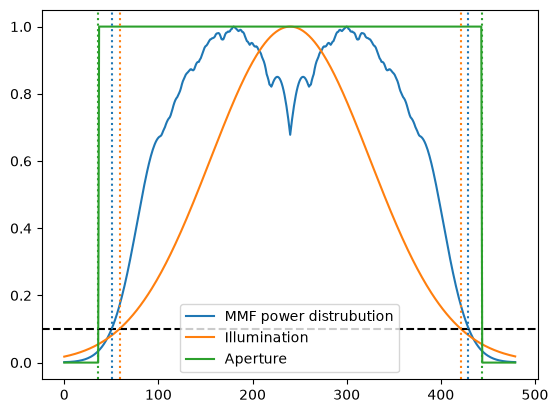

In [17]:
modes_cut = incohe_modes_SLM[cc, :]
illum_cut = illumination_norm[cc, :]

def threshold_edges(y, level):
    inside = flatnonzero(y >= level)
    return inside[0], inside[-1]

aperture_diameter_um = 7.5e3
pixel_um = gs_engine.opticalsetup.slm_pixel_size * gs_engine.masksetup.downscale
radius_px = (aperture_diameter_um / 2) / pixel_um
x = arange(modes_cut.size)
aperture = (abs(x - cc) <= radius_px).astype(float)

plot(modes_cut, label = 'MMF power distrubution')
plot(illum_cut, label = 'Illumination')
plot(aperture, color="C2", label = 'Aperture')
axhline(thr, color="k", ls="--")

for x_edge in threshold_edges(modes_cut, thr):
    print(x_edge)
    axvline(x_edge, color="C0", ls=":")
for x_edge in threshold_edges(illum_cut, thr):
    axvline(x_edge, color="C1", ls=":")
axvline(cc - radius_px, color="C2", ls=":")
axvline(cc + radius_px, color="C2", ls=":")

legend()

In [216]:
gs_engine = gui.engine
gs_engine.feasibility_setup_check()

--------------------------------
Feasibility setup integritycheck:
Illumination outside pupil power: 0.29 % --> True
Modes outside aperture power: 2.39 % --> False
Illumination overlap support: False
Setup feasible?  False
This system will only support up to NA_MMF: 0.20
--------------------------------


In [14]:
gs_engine.get_gs_properties()

{'engine_mode': 'fibremodes',
 'mode_basis': 'LG',
 'gs_ready': True,
 'maskcount': 66,
 'number_of_modes': 36,
 'mode_range': None,
 'slm_size_um': 8832.0,
 'artificial_slm_size_um': 8832.0,
 'spatial_resolution_per_um': 0.05434782608695652,
 'image_plane_samples': 480,
 'useful_slm_samples': 480,
 'slm_pixel_size_um': 9.2,
 'pixel_size_fft_um': 0.9550498188405797,
 'max_spectral_distance_um': 229.0,
 'beam_waist_slm_um': 2200.0,
 'beam_waist_mode': 'Custom Beam Waist',
 'core_diameter_um': 23.0,
 'core_radius_um': 11.5,
 'forbidden_radius_um': 34.5,
 'pupil_radius_um': 3750.0,
 'illumination_outside_pupil_power': 0.0028763969000146308,
 'illumination_pow_check_passed': True,
 'mode_basis_power_outside_pupil': 0.00015556150174234062,
 'modes_pow_check_passed': True,
 'illumination_overlap_support_passed': True,
 'setup_feasible': True,
 'NA_MMF_system_max': 0.2,
 'ill_coverage_radius_px': 240.0,
 'modes_coverage_radius_px': 217.0}

(<matplotlib.image.AxesImage at 0x29e1b2e29d0>,
 <matplotlib.colorbar.Colorbar at 0x29e1b23ca10>)

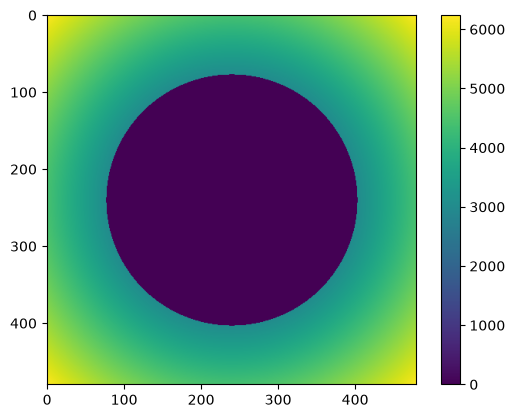

ENGINE MODE SELECTED: fibremodes
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 0.9550498188405797 um
MAX spectral distance +- 229.0 um
Beam waist in the SLM --> 2.2  mm , Calculated via:  Custom Beam Waist
Forbiden area r < 34.5 um
Generating modes coeficients...
Generating modes...
Engine : GPU
Mem. avaliable  7.9970703125  mem. needed  0.30590057373046875  in Gb
Generating rest of the modes...
MODES RANGE: None
Fibre modes engine mode selected: memory allocation for 153 masks --> number of modes 81


In [ ]:
R = gs_engine.illumination._R
RR = R
RR[R <= 7.5//2 * 1e3] = 0
imshow(RR),colorbar()

In [ ]:
from gs import GS, GS_mask_setup, optical_setup
from gs.ui import GSWidget

optical = optical_setup(
    wavelength=1.3,
    fin=25e3,
    fout=8e3,
    masksize=960,
    slm_pixel_size=9.2,
    MMF_mfd=12.2,
    MMF_diameter=62.5,
    MMF_mode_groups=22,
    mode_basis="LG",
)
masksetup = GS_mask_setup(
    num_masks=2,
    convergence_metric="overlap",
    goal_value=0.99,
    downscale=2,
    upsample=0,
    MAX_iterations=300,
)
gs_engine = GS(optical, masksetup, engine_mode="fields", number_masks=2)
gui = GSWidget(gs_engine)
gui.show()

ENGINE MODE SELECTED: fields
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 1.1775362318840579 um
MAX spectral distance +- 282.0 um
Beam waist in the SLM --> 1.9450254011992316  mm , Calculated via:  Single Mode Fiber
Forbiden area r < 125.0 um
Generating modes coeficients...
Generating modes...
Engine : GPU
Mem. avaliable  8.7607421875  mem. needed  0.49850463867187506  in Gb
Generating rest of the modes...
Fields engine mode selected: memory allocation for 2 masks


ENGINE MODE SELECTED: fields
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 1.1775362318840579 um
MAX spectral distance +- 282.0 um
Beam waist in the SLM --> 1.9450254011992316  mm , Calculated via:  Single Mode Fiber
Forbiden area r < 125.0 um
Generating modes coeficients...
Generating modes...
Engine : GPU
Mem. avaliable  8.7607421875  mem. needed  0.49850463867187506  in Gb
Generating rest of the modes...
Fields engine mode selected: memory allocation for 2 masks
ENGINE MODE SELECTED: fibremodes
SLM size = 8832.0 um
Artificial SLM size = 8832.0 um
Spatial resolution 0.05434782608695652 um-1
Image plane samples 480 x 480
Useful SLM samples 480 x 480
Pixel size FFT 1.1775362318840579 um
MAX spectral distance +- 282.0 um
Beam waist in the SLM --> 1.9450254011992316  mm , Calculated via:  Single Mode Fiber
Forbiden area r < 125.0 um
Generating modes coeficients...
